<div align="center" style="padding:40px 24px;background:linear-gradient(135deg,#0e1a2e 0%,#13223b 100%);border-radius:14px;border-bottom:5px solid #ffd43b;">
  <p style="margin:0;color:#6aaef0;font-family:monospace;font-weight:700;font-size:14px;letter-spacing:.16em;text-transform:uppercase;">The AI Learning Hub · Lição 02 · Machine Learning: fundamentos</p>
  <h1 style="margin:14px 0 6px;color:#f1f5fb;font-size:42px;">01 · CRISP-DM: preços de casas</h1>
  <p style="margin:0;color:#b4c2d8;font-size:18px;">Que fatores mais pesam no preço de uma casa?</p>
</div>

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/the-ai-learning-hub/02-machine-learning-fundamentals/blob/main/01_supervised_learning/notebooks/01_CRISP-DM_House_Prices.ipynb) [![Slides](https://img.shields.io/badge/slides-Lição_02-ffd43b)](https://the-ai-learning-hub.github.io/02-machine-learning-fundamentals/#supervisionada)

## 🎯 Objetivos de aprendizagem
Ao terminares este notebook, vais conseguir:

- percorrer as **6 fases do CRISP-DM** num problema de **regressão** real (546 casas de Windsor, Canadá, 1987);
- explorar os dados com olhos críticos: distribuições, correlações, *outliers*, e a diferença entre **correlação e causa**;
- preparar os dados **sem fugas de informação** (*data leakage*): dividir primeiro, ajustar depois, tudo dentro de um *pipeline*;
- comparar um *baseline*, um modelo linear, a Ridge e uma *random forest* com **validação cruzada**, e perceber a relação entre complexidade e *overfitting*;
- avaliar com MAE, RMSE, R² e MAPE, ler os coeficientes como **percentagens** e investigar onde o modelo falha;
- guardar o modelo, expô-lo como função `predict_price(...)` e discutir os seus **limites** (1987!, deriva, previsão vs causa).

**⏱️ Duração estimada:** ≈ 45 min · **📋 Pré-requisitos:** Python básico, `pandas` e noções de média/desvio-padrão · **▶️ Como usar:** executa cada célula com `Shift`+`Enter`, por ordem.

## 📑 Índice

1. [🧭 Business Understanding (compreensão do negócio)](#sec-1)
2. [🔎 Data Understanding (compreensão dos dados)](#sec-2)
3. [🧹 Data Preparation (preparação dos dados)](#sec-3)
4. [🤖 Modeling (modelação)](#sec-4)
5. [📏 Evaluation (avaliação)](#sec-5)
6. [🚀 Deployment (implementação)](#sec-6)
7. [🎁 Pergunta-bónus: devo remodelar?](#sec-7)
8. [📌 Resumo](#sec-8)
9. [📚 Para saber mais](#sec-9)

<a id="sec-0"></a>
## ⚙️ Preparar o ambiente

In [1]:
# ⚙️ Preparar o ambiente: funciona localmente (VS Code/Jupyter) e no Google Colab
import subprocess
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    ROOT = Path("/content/02-machine-learning-fundamentals")
    if not ROOT.exists():
        subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/the-ai-learning-hub/02-machine-learning-fundamentals.git",
                        str(ROOT)], check=True)
else:
    ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir() and (p / "data").is_dir())

try:  # o Colab já traz tudo; localmente usa `uv sync` (ver README)
    import sklearn, seaborn  # noqa: F401
except ImportError:  # plano B: instala as dependências declaradas no pyproject.toml
    import tomllib
    deps = tomllib.loads((ROOT / "pyproject.toml").read_text(encoding="utf-8"))["project"]["dependencies"]
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *deps], check=True)

sys.path.insert(0, str(ROOT))
print("Raiz do projeto:", ROOT.name, "(Colab)" if IN_COLAB else "(local)")

Raiz do projeto: 02-machine-learning-fundamentals (local)


> 🗺️ **O fio condutor.** O **CRISP-DM** (*Cross-Industry Standard Process for Data Mining*, 1999/2000) organiza um projeto de dados em 6 fases: **Business Understanding** (compreensão do negócio) → **Data Understanding** (compreensão dos dados) → **Data Preparation** (preparação dos dados) → **Modeling** (modelação) → **Evaluation** (avaliação) → **Deployment** (implementação). As setas voltam atrás muitas vezes: raramente se acerta à primeira. Neste notebook vais passar por cada fase, com um cabeçalho explícito, e em cada uma há pelo menos uma **💬 Discussão**.

<a id="vocab"></a>
## 📖 Vocabulário essencial (lê isto primeiro!)
Se é a tua primeira vez em *machine learning*, estas palavras vão aparecer o tempo todo. Volta aqui sempre que precisares.

| Termo | Em palavras simples | Exemplo neste notebook |
|---|---|---|
| **Dataset** (conjunto de dados) | Uma tabela com exemplos | As 546 casas de Windsor |
| **Linha** (exemplo, observação) | Um caso concreto | Uma casa |
| **Feature** (característica) | Uma coluna que o modelo usa para prever | `lotsize`, `bathrooms`, `aircon` |
| **Alvo / *label*** | A coluna que queremos prever | `price` (o preço) |
| **Modelo** | Uma "receita" matemática que transforma *features* numa previsão | Regressão linear, floresta aleatória |
| **Treinar** (`fit`) | Deixar o modelo ajustar-se aos exemplos para errar menos | `modelo.fit(X_treino, y_treino)` |
| **Prever** (`predict`) | Usar o modelo treinado em casos novos | `modelo.predict(X_teste)` |
| **Erro** | Diferença entre o que o modelo prevê e o valor real | Prevê 60 000 CAD, vale 65 000: erro de 5 000 CAD |
| **Baseline** | O modelo mais simples possível (aqui: prever sempre a média); o mínimo a bater | "Esta casa vale sempre 68 122 CAD" |
| ***Overfitting*** (sobreajuste) | O modelo decora o treino e falha em dados novos | Árvore profunda: erro de treino quase 0, validação alta |
| **Treino / teste** (*split*) | Parte dos dados para aprender e parte "escondida" para avaliar de forma honesta | 80 % / 20 % |
| **Validação cruzada** | Repetir treino/validação em várias partições (*folds*) para ter uma estimativa mais fiável | 5 *folds* |
| ***Pipeline*** | Sequência de passos (preparar dados → modelo) que se treina e aplica de uma vez | `make_pipeline(pré-processador, modelo)` |
| ***Data leakage*** (fuga) | Informação do teste (ou do futuro) a "passar" para o treino | Estandardizar antes de dividir |
| **Resíduo** | Erro de uma previsão (real − previsto) | Ver gráfico de resíduos |
| ***Outlier*** | Valor muito diferente dos outros | Casas de luxo |
| **Logaritmo (log)** | Transforma multiplicações em somas; útil para valores muito assimétricos | `log(preço)` |

In [2]:
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, cross_validate, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeRegressor

from src.data import HOUSING_BINARY, HOUSING_NUMERIC, load_housing
from src.paths import assets_dir, models_dir
from src.plotting import MARKERS, PALETTE, apply_style, fmt_pt, label_bars, plot_residuals, pt_axis, save_fig
from src.preprocessing import make_housing_preprocessor

apply_style()
FIG = assets_dir("figures")  # figuras que também aparecem nos slides
def fmt_sgn(v, d=0):
    """Número com sinal explícito, em formato PT."""
    return ("+" if v >= 0 else "−") + fmt_pt(abs(v), d)
print("Pronto.")

Pronto.


<a id="sec-1"></a>
# 1. 🧭 Business Understanding (compreensão do negócio)

Antes de abrir um único ficheiro de dados, pergunta-te: **quem vai usar isto, para decidir o quê, e o que é "suficientemente bom"?** Esta é a fase que mais projetos saltam, e a que mais projetos estraga.

### Quem usa uma previsão de preço de casas?

| Utilizador | Decisão | O que lhe interessa |
|---|---|---|
| 🏠 **Comprador / vendedor** | Quanto oferecer ou pedir? | Um intervalo realista; saber se o preço pedido está "fora" |
| 🧑‍💼 **Agente imobiliário** | Em que preço anunciar? | Rapidez; saber **que características** justificam o preço |
| 🏦 **Banco** | Quanto emprestar contra esta garantia? | Erro **pequeno em média** e sem grandes surpresas para baixo (sobrevalorizar = risco) |

### O que é "bom"?
Uma métrica sem contexto não diz nada. "R² = 0,64" é bom? Depende de **quanto custa errar**. Convém fixar *antes* de modelar:

- **Erro típico aceitável em dólares.** O preço mediano nestes dados ronda os 62 000 CAD; um erro típico de 5 000 CAD é irrelevante para um banco, mas 25 000 CAD já são 40 % do preço de uma casa mediana.
- **Erro relativo tolerável.** Num mercado de casas, um erro de **10-15 %** é o que um avaliador humano rápido consegue; abaixo disso é "muito bom", acima de 25 % deixa de servir para decidir.
- **Comparação com um *baseline*.** O modelo tem de bater a estratégia mais simples (prever sempre a média).

> 🎯 **Pergunta de negócio:** *que fatores mais pesam no preço de uma casa?* É uma pergunta **explicativa** ("o que pesa?") e **preditiva** ("quanto vale?"). Vamos ver que as duas não são a mesma coisa.

### ✍️ As tuas hipóteses (antes de ver os dados!)
Preenche o dicionário abaixo com a tua intuição. Não há respostas erradas: o objetivo é **comparar no fim** o que achavas com o que os dados mostram (e perceber onde a intuição enganou).

In [3]:
# ✍️ Escreve as tuas hipóteses ANTES de explorar os dados. Substitui os valores e volta a executar.
my_hypotheses = {
    "fator_que_mais_pesa": "",        # ex.: "lotsize", "bathrooms", "aircon", ...
    "segundo_fator": "",
    "fator_que_menos_pesa": "",
    "aircon_valoriza_em_%": None,     # quantos % mais cara é uma casa com ar condicionado? (ex.: 15)
    "erro_aceitavel_em_%": None,      # que erro relativo médio aceitarias de um modelo? (ex.: 15)
}
preenchido = {k: v for k, v in my_hypotheses.items() if v not in ("", None)}
print(f"Hipóteses registadas: {len(preenchido)} de {len(my_hypotheses)}")
print(my_hypotheses)

Hipóteses registadas: 0 de 5
{'fator_que_mais_pesa': '', 'segundo_fator': '', 'fator_que_menos_pesa': '', 'aircon_valoriza_em_%': None, 'erro_aceitavel_em_%': None}


### 💬 Discussão — O que é um erro aceitável?
Um banco e um comprador particular usam o mesmo modelo de preços. Devem aceitar o **mesmo** erro? E um erro de +10 000 CAD é tão grave como um de −10 000 CAD?

<details>
<summary>🧑‍🏫 Resposta-guia para o instrutor</summary>

Não. O banco empresta contra o valor estimado, por isso **sobrestimar** é o erro caro (empresta demais); o comprador particular tem receio do contrário se for vendedor. Isto mostra que a escolha da **métrica** e do **tipo de erro** é uma decisão de negócio, não técnica. Mais à frente vamos ver que o nosso modelo tem um erro relativo médio (MAPE) de cerca de **17,5 %**: acima dos 10-15 % que sugerimos como "muito bom", mas suficiente para uma **triagem** ("esta casa está claramente cara/barata?"), não para fixar um empréstimo. Dizer isto *antes* de modelar evita a tentação de ajustar a fasquia ao resultado.
</details>

<a id="sec-2"></a>
# 2. 🔎 Data Understanding (compreensão dos dados)

### 🗂️ Conhecer os dados
Antes de modelar, **conhece o teu material**. Esta é a "ficha do dataset":

| | |
|---|---|
| **O que é** | Os dados de venda de **546 casas** usados num estudo clássico de economia sobre o que determina o preço de uma casa |
| **De onde vem** | Arquivo de dados oficial do *Journal of Applied Econometrics* (Anglin & Gençay, 1996): <http://qed.econ.queensu.ca/jae/1996-v11.6/anglin-gencay/>. É **descarregado no primeiro uso** para a pasta `data/` do projeto |
| **Quando e onde** | Casas vendidas em **Windsor, Ontário (Canadá)**, entre **julho e setembro de 1987** |
| **Uma linha =** | uma casa vendida |
| **Alvo =** | `price`, o preço de venda |
| **Tamanho** | 546 linhas × 12 colunas, sem valores em falta |
| **Unidades** | preço em **dólares canadianos de 1987 (CAD)**, que não são comparáveis com preços de hoje; áreas em **pés²** (1 pé² ≈ 0,093 m²) |

Todas as colunas, em português:

| Coluna | Significado | Tipo | Exemplo | Unidade |
|---|---|---|---|---|
| `price` | preço de venda (**o alvo**) | número | 42 000 | CAD de 1987 |
| `lotsize` | área do **lote** (terreno), não da casa | número | 5 850 | pés² |
| `bedrooms` | n.º de quartos | contagem | 3 | quartos |
| `bathrooms` | n.º de casas de banho | contagem | 1 | casas de banho |
| `stories` | n.º de pisos | contagem | 2 | pisos |
| `driveway` | tem entrada de automóvel (acesso privado)? | sim/não | yes | n/a |
| `recreation` | tem sala de lazer/recreio? | sim/não | no | n/a |
| `fullbase` | tem cave completa? | sim/não | yes | n/a |
| `gasheat` | tem água quente aquecida a gás? | sim/não | no | n/a |
| `aircon` | ar condicionado central? | sim/não | no | n/a |
| `garage` | n.º de lugares de garagem | contagem | 1 | lugares |
| `prefer` | está num bairro **preferencial**? | sim/não | no | n/a |

> ⚠️ **Cuidado:** `prefer` é a **única** variável de localização. Não sabemos a rua, a distância ao centro, nem o ano de construção.

In [4]:
df = load_housing()
print(f"{df.shape[0]} casas, {df.shape[1]} colunas · NAs: {int(df.isna().sum().sum())} · linhas totalmente repetidas: {int(df.duplicated().sum())}")
df.head()

546 casas, 12 colunas · NAs: 0 · linhas totalmente repetidas: 1


,price,lotsize,bedrooms,bathrooms,stories,driveway,recreation,fullbase,gasheat,aircon,garage,prefer
0,42000,5850,3,1,2,yes,no,yes,no,no,1,no
1,38500,4000,2,1,1,yes,no,no,no,no,0,no
2,49500,3060,3,1,1,yes,no,no,no,no,0,no
3,60500,6650,3,1,2,yes,yes,no,no,no,0,no
4,61000,6360,2,1,1,yes,no,no,no,no,0,no


Uma figura-resumo, **uma coluna por painel** (histogramas para números, barras para contagens e sim/não):

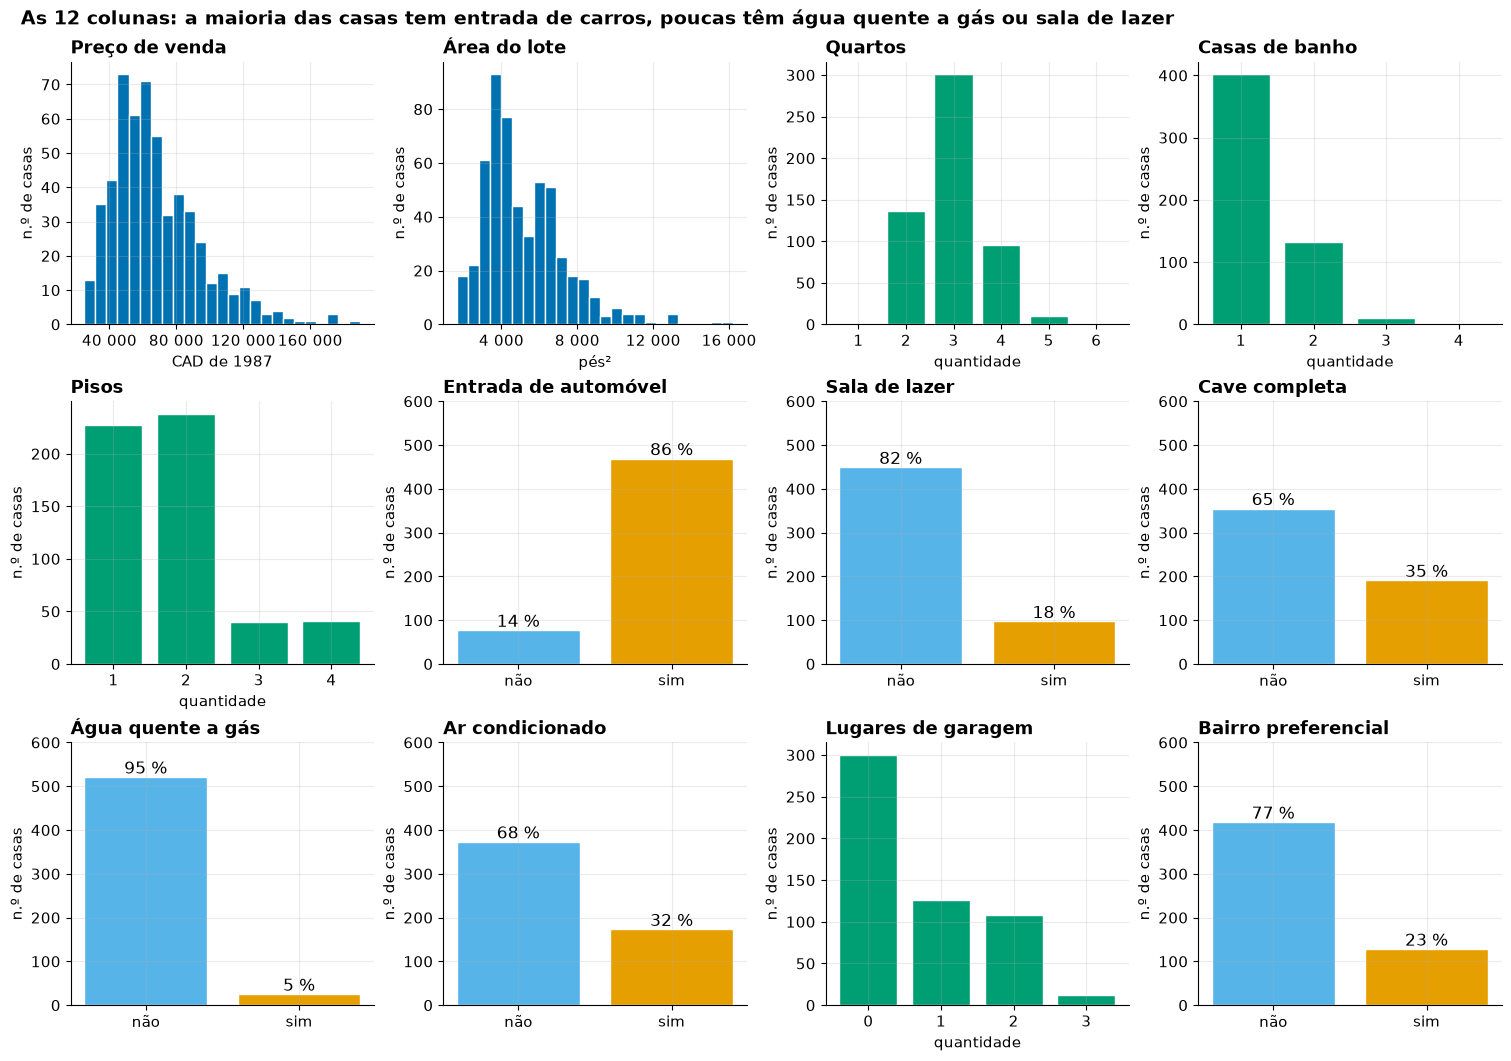

In [5]:
TITULOS = {"price": "Preço de venda", "lotsize": "Área do lote", "bedrooms": "Quartos", "bathrooms": "Casas de banho",
           "stories": "Pisos", "driveway": "Entrada de automóvel", "recreation": "Sala de lazer", "fullbase": "Cave completa",
           "gasheat": "Água quente a gás", "aircon": "Ar condicionado", "garage": "Lugares de garagem", "prefer": "Bairro preferencial"}
fig, axes = plt.subplots(3, 4, figsize=(15, 10.5), layout="constrained")
for ax, col in zip(axes.flat, df.columns):
    if col in ("price", "lotsize"):
        ax.hist(df[col], bins=25, color=PALETTE["blue"], edgecolor="white")
        ax.set(xlabel="CAD de 1987" if col == "price" else "pés²", ylabel="n.º de casas")
    elif col in ("bedrooms", "bathrooms", "stories", "garage"):
        vc = df[col].value_counts().sort_index()
        ax.bar(vc.index.astype(str), vc.values, color=PALETTE["green"], edgecolor="white")
        ax.set(xlabel="quantidade", ylabel="n.º de casas")
    else:
        vc = df[col].value_counts().reindex(["no", "yes"])
        ax.bar(["não", "sim"], vc.values, color=[PALETTE["sky"], PALETTE["orange"]], edgecolor="white")
        for x, v in enumerate(vc.values):
            ax.text(x, v + 8, f"{fmt_pt(100 * (v / len(df)), 0)} %", ha="center", fontsize=12)
        ax.set(ylabel="n.º de casas", ylim=(0, 600))
    ax.set_title(TITULOS[col], fontsize=13)
    ax.tick_params(labelsize=11)
    ax.xaxis.label.set_size(11)
    ax.yaxis.label.set_size(11)
    if col in ("price", "lotsize"):
        pt_axis(ax, "x", 0, 5)
fig.suptitle("As 12 colunas: a maioria das casas tem entrada de carros, poucas têm água quente a gás ou sala de lazer", x=0.01, ha="left", fontweight="bold", fontsize=14)
save_fig(fig, FIG / "01_dataset_overview.png")
plt.show()

**Como ler:** o preço e o lote têm uma "cauda" à direita (poucas casas muito grandes/caras); a casa típica tem 3 quartos, 1 casa de banho e 1-2 pisos; quase 9 em 10 casas têm entrada de carros (`driveway`), mas só ≈ 5 % têm água quente a gás (`gasheat`).

In [6]:
df.describe().T[["mean", "std", "min", "50%", "max"]].round(1)

,mean,std,min,50%,max
price,68121.6,26702.7,25000.0,62000.0,190000.0
lotsize,5150.3,2168.2,1650.0,4600.0,16200.0
bedrooms,3.0,0.7,1.0,3.0,6.0
bathrooms,1.3,0.5,1.0,1.0,4.0
stories,1.8,0.9,1.0,2.0,4.0
garage,0.7,0.9,0.0,0.0,3.0


### 2.1 Distribuição do preço
O preço é uma variável **positiva e assimétrica** (poucas casas muito caras). Isto afeta o que um modelo aprende e a métrica que escolhemos.

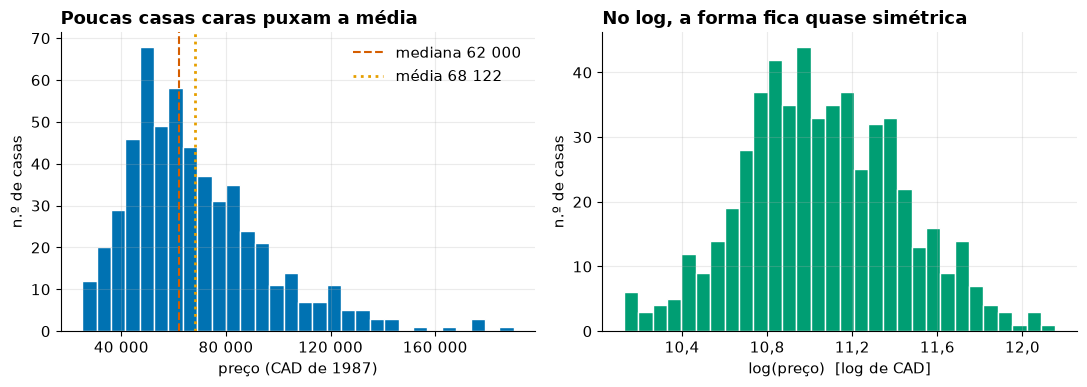

Assimetria (skew): preço 1,21 · log(preço) 0,14


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(df["price"], bins=30, color=PALETTE["blue"], edgecolor="white")
axes[0].axvline(df["price"].median(), color=PALETTE["red"], ls="--", label=f"mediana {fmt_pt(df['price'].median(), 0)}")
axes[0].axvline(df["price"].mean(), color=PALETTE["orange"], ls=":", lw=2, label=f"média {fmt_pt(df['price'].mean(), 0)}")
axes[0].set(xlabel="preço (CAD de 1987)", ylabel="n.º de casas", title="Poucas casas caras puxam a média")
axes[0].legend()
axes[1].hist(np.log(df["price"]), bins=30, color=PALETTE["green"], edgecolor="white")
axes[1].set(xlabel="log(preço)  [log de CAD]", ylabel="n.º de casas", title="No log, a forma fica quase simétrica")
pt_axis(axes[0], "x", 0, 5)
pt_axis(axes[1], "x", 1, 6)
fig.tight_layout()
save_fig(fig, FIG / "01_price_distribution.png")
plt.show()
print(f"Assimetria (skew): preço {fmt_pt(df['price'].skew(), 2)} · log(preço) {fmt_pt(np.log(df['price']).skew(), 2)}")

> 💡 **Dica:** com um alvo assimétrico, um mesmo erro absoluto "pesa" mais numa casa barata do que numa cara. Prever o **logaritmo** do preço faz o modelo pensar em **percentagens** ("+20 %") em vez de dólares fixos, e costuma estabilizar os resíduos. Vamos usar isto na preparação.

### 2.2 Correlações

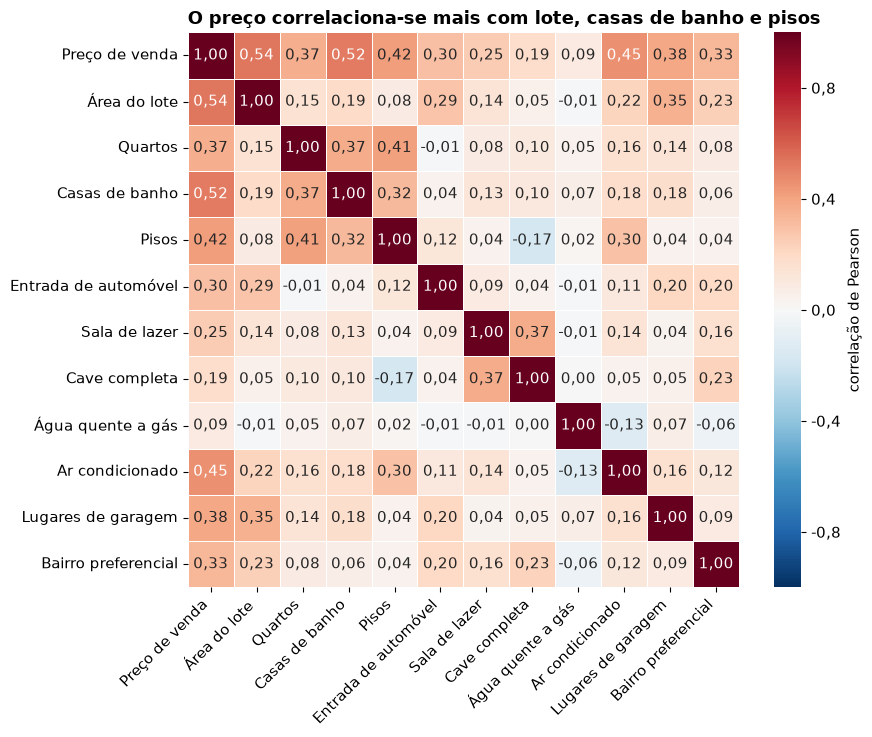

,lotsize,bathrooms,aircon,stories,garage,bedrooms,prefer,driveway,recreation,fullbase,gasheat
corr com price,0.54,0.52,0.45,0.42,0.38,0.37,0.33,0.3,0.25,0.19,0.09


In [8]:
num = df.copy()
for c in HOUSING_BINARY:                 # sim/não → 1/0 só para calcular correlações
    num[c] = (num[c] == "yes").astype(int)
corr = num.corr()
fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(corr, annot=corr.map(lambda v: fmt_pt(v, 2)).values, fmt="", cmap="RdBu_r", vmin=-1, vmax=1, linewidths=.5, cbar_kws={"label": "correlação de Pearson"}, ax=ax)
ax.set_title("O preço correlaciona-se mais com lote, casas de banho e pisos")
ax.grid(False)
pt_axis(ax.collections[0].colorbar.ax, "y", 1, 5)
ax.set_xticklabels([TITULOS[c] for c in corr.columns], rotation=45, ha="right")
ax.set_yticklabels([TITULOS[c] for c in corr.index], rotation=0)
fig.tight_layout()
save_fig(fig, FIG / "01_correlations.png")
plt.show()
corr["price"].drop("price").sort_values(ascending=False).round(2).to_frame("corr com price").T

### 2.3 Preço por característica (caixas de bigodes)

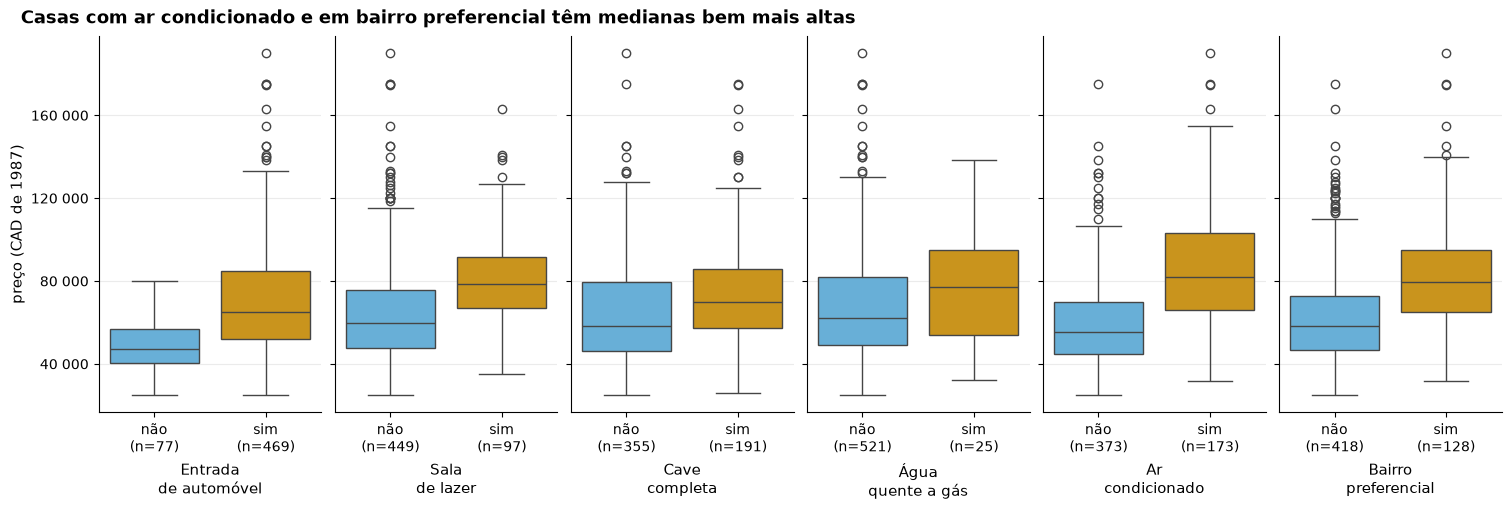

aircon,no,yes
preço mediano (CAD),55500.0,82000.0


In [9]:
fig, axes = plt.subplots(1, 6, figsize=(15, 5), sharey=True, layout="constrained")
for ax, col in zip(axes, HOUSING_BINARY):
    sns.boxplot(data=df, x=col, y="price", order=["no", "yes"], hue=col, hue_order=["no", "yes"],
                palette=[PALETTE["sky"], PALETTE["orange"]], legend=False, ax=ax)
    n = df[col].value_counts()
    ax.set_xticks([0, 1], [f"não\n(n={n['no']})", f"sim\n(n={n['yes']})"])
    ax.set(xlabel=TITULOS[col].replace(" ", "\n", 1), ylabel="preço (CAD de 1987)" if col == HOUSING_BINARY[0] else "")
    ax.tick_params(labelsize=10)
fig.suptitle("Casas com ar condicionado e em bairro preferencial têm medianas bem mais altas", x=0.01, ha="left", fontweight="bold")
pt_axis(axes[0], "y", 0, 6)
save_fig(fig, FIG / "01_boxplots_binary.png")
plt.show()
df.groupby("aircon")["price"].median().to_frame("preço mediano (CAD)").T

### 2.4 *Outliers*: erro, ou casa de luxo?

In [10]:
q1, q3 = df["price"].quantile([.25, .75])
limite = q3 + 1.5 * (q3 - q1)
altos = df[df["price"] > limite].sort_values("price", ascending=False)
print(f"Regra do IQR: preço > {fmt_pt(limite, 0)} CAD → {len(altos)} casas ({fmt_pt(100 * (len(altos) / len(df)), 1)} %).")
altos.head(5)

Regra do IQR: preço > 131 312 CAD → 15 casas (2,7 %).


,price,lotsize,bedrooms,bathrooms,stories,driveway,recreation,fullbase,gasheat,aircon,garage,prefer
377,190000,7420,4,2,3,yes,no,no,no,yes,2,yes
362,175000,9960,3,2,2,yes,no,yes,no,no,2,yes
331,175000,8960,4,4,4,yes,no,no,no,yes,3,no
418,174500,7500,4,2,2,yes,no,yes,no,yes,3,yes
92,163000,7420,4,1,2,yes,yes,yes,no,yes,2,no


Estas casas são caras mas **plausíveis** (lotes grandes, várias casas de banho, bairro preferencial): são **casas de luxo reais**, não erros de introdução. Apagá-las tornaria o modelo pior precisamente onde o dinheiro está. Regra: **investiga antes de remover**, e só removes se for um erro demonstrável.

### 2.5 Primeiras surpresas

Mediana do lote (pés²) e do preço (CAD) por n.º de casas de banho:


,casas,lote_mediano,preco_mediano
bathrooms,,,
1,402,4320.0,57125.0
2,133,6000.0,87000.0
3,10,5980.0,104500.0
4,1,8960.0,175000.0


Correlação lotsize × bathrooms: 0.19


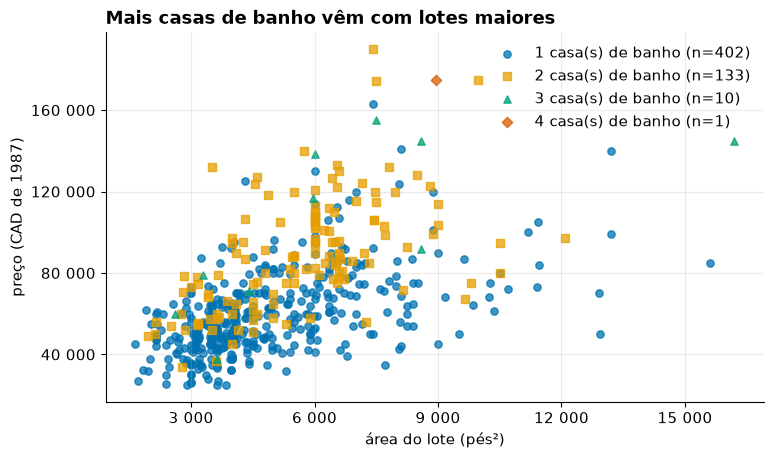

In [11]:
print("Mediana do lote (pés²) e do preço (CAD) por n.º de casas de banho:")
display(df.groupby("bathrooms").agg(casas=("price", "size"), lote_mediano=("lotsize", "median"), preco_mediano=("price", "median")))
print("Correlação lotsize × bathrooms:", round(num["lotsize"].corr(num["bathrooms"]), 2))

fig, ax = plt.subplots(figsize=(8.5, 4.8))
for b, marker, color in zip([1, 2, 3, 4], MARKERS, ["blue", "orange", "green", "red"]):
    sub = df[df["bathrooms"] == b]
    ax.scatter(sub["lotsize"], sub["price"], marker=marker, s=28, alpha=.75, color=PALETTE[color], label=f"{b} casa(s) de banho (n={len(sub)})")
ax.set(xlabel="área do lote (pés²)", ylabel="preço (CAD de 1987)", title="Mais casas de banho vêm com lotes maiores")
ax.legend()
pt_axis(ax, "x", 0, 6)
pt_axis(ax, "y", 0, 6)
save_fig(fig, FIG / "01_lotsize_bathrooms.png")
plt.show()

In [12]:
print("Lote mediano (pés²) com/sem ar condicionado e em bairro preferencial:")
display(df.groupby("aircon")["lotsize"].median().to_frame("lote mediano").T)
display(df.groupby("prefer")["lotsize"].median().to_frame("lote mediano").T)
print("Proporção de casas com ar condicionado, por bairro preferencial ou não:")
display(pd.crosstab(df["prefer"], df["aircon"], normalize="index").round(2))

Lote mediano (pés²) com/sem ar condicionado e em bairro preferencial:


aircon,no,yes
lote mediano,4050.0,6000.0


prefer,no,yes
lote mediano,4310.0,6360.0


Proporção de casas com ar condicionado, por bairro preferencial ou não:


aircon,no,yes
prefer,,
no,0.71,0.29
yes,0.59,0.41


### 2.6 Correlação ≠ causa, e o que **falta**
Os dados mostram que casas com ar condicionado são mais caras, mas **não** provam que *instalar* ar condicionado sobe o preço: essas casas são também maiores, estão em melhores bairros, etc. (**variáveis de confusão**, *confounders*). Há ainda informação que um comprador usaria e que **não temos**:

- **localização exata** (rua, distância ao centro e às escolas); `prefer` é um substituto grosseiro;
- **ano de construção** e estado de conservação;
- **área habitável** (só temos a área do **lote**, não a da casa);
- qualidade de acabamentos, luz, vistas, negociação.

Estes fatores ocultos vão traduzir-se em **erro irredutível**: nenhum modelo, por mais sofisticado, os recupera a partir destas 11 colunas.

### 💬 Discussão — O que nos dizem (e não dizem) as primeiras surpresas?
Olha para `bathrooms`, `lotsize`, `aircon` e `prefer`. Porque é que não podemos dizer "cada casa de banho extra acrescenta X ao preço" olhando só para a tabela de medianas?

<details>
<summary>🧑‍🏫 Resposta-guia para o instrutor</summary>

As casas com 2 casas de banho têm preço mediano **87 000** contra **57 125** com 1, mas também têm lote mediano de **6 000** pés² contra **4 320**: mais casas de banho vêm "no pacote" de casas maiores, em lotes maiores. A tabela mistura o efeito da casa de banho com o do tamanho. O mesmo vale para `aircon`: mediana **82 000 vs 55 500 CAD**, mas as casas com ar condicionado concentram-se em bairros preferenciais e em lotes maiores (ver tabelas acima). Só um modelo que **controle** os outros fatores (regressão múltipla) ajuda a separar efeitos, e mesmo assim só dentro das variáveis observadas. Falta área habitável, localização e ano de construção: o que o modelo atribui a `bathrooms` pode estar a "absorver" área habitável.
</details>

<a id="sec-3"></a>
# 3. 🧹 Data Preparation (preparação dos dados)

Regra de ouro: **qualquer coisa que "aprenda" com os dados** (médias para estandardizar, categorias para codificar, o próprio modelo) deve ser ajustada **apenas com o treino**. Por isso:

1. **Dividir primeiro** em treino (80 %) e teste (20 %); o teste fica "no cofre" até à avaliação final.
2. Todo o pré-processamento vive dentro de um ***pipeline*** (`make_housing_preprocessor`): estandardiza as variáveis numéricas e codifica sim/não em 0/1. Na validação cruzada é reajustado em cada *fold*, sem espreitar a parte de validação.
3. Prever o **log do preço** com `TransformedTargetRegressor`: o modelo treina em log, mas **devolve previsões em CAD** (aplica `exp` automaticamente).
4. Usar **só variáveis disponíveis no momento da previsão**. Aqui todas as 11 colunas são conhecidas antes da venda; se houvesse uma coluna como "desconto final negociado" seria *leakage*.

In [13]:
X = df.drop(columns="price")
y = df["price"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Treino: {len(X_train)} casas · Teste: {len(X_test)} casas")
print(f"Preço mediano  treino {fmt_pt(y_train.median(), 0)}  ·  teste {fmt_pt(y_test.median(), 0)}")

Treino: 436 casas · Teste: 110 casas
Preço mediano  treino 62 900  ·  teste 59 500


In [14]:
# O que faz o pré-processador? Ajustado SÓ ao treino; o teste usa a média/desvio do treino.
pre = make_housing_preprocessor()
Z_train = pd.DataFrame(pre.fit_transform(X_train), columns=pre.get_feature_names_out(), index=X_train.index)
print("Médias das colunas numéricas (treino) depois de estandardizar:", Z_train[HOUSING_NUMERIC].mean().round(2).tolist())
Z_train.head(3)

Médias das colunas numéricas (treino) depois de estandardizar: [-0.0, -0.0, 0.0, 0.0, -0.0]


,lotsize,bedrooms,bathrooms,stories,garage,driveway_yes,recreation_yes,fullbase_yes,gasheat_yes,aircon_yes,prefer_yes
93,1.521022,0.038775,1.447943,2.528447,1.492872,1.0,0.0,0.0,0.0,1.0,0.0
335,1.182614,-1.370053,-0.562576,-0.934599,0.330564,1.0,0.0,0.0,0.0,0.0,0.0
412,0.528977,0.038775,1.447943,2.528447,-0.831743,1.0,0.0,0.0,0.0,1.0,1.0


> ⚠️ **Cuidado:** estandardizar o conjunto **todo** antes de dividir é uma fuga subtil: a média do teste "contamina" o treino. O *pipeline* evita este erro por construção.

### 💬 Discussão — Porque é que o log do preço ajuda?
Treinar com `log(preço)` e depois voltar a CAD parece uma complicação. O que ganhamos? E o que muda na interpretação dos coeficientes?

<details>
<summary>🧑‍🏫 Resposta-guia para o instrutor</summary>

O preço tem assimetria **1,21**; o log traz-a para perto de 0 (ver gráfico em 2.1). Ganhamos (i) erros mais homogéneos entre casas baratas e caras e (ii) um modelo **multiplicativo**: cada característica multiplica o preço por um fator ("+20 % com ar condicionado") em vez de somar dólares fixos, o que é mais realista (uma casa de banho vale mais numa casa cara). O custo é que o coeficiente deixa de estar em CAD: passa a ler-se como `exp(coef) − 1` em percentagem, como veremos na avaliação. E como avaliamos sempre em CAD, o `TransformedTargetRegressor` garante que comparamos tudo na mesma unidade.
</details>

<a id="sec-4"></a>
# 4. 🤖 Modeling (modelação)

Vamos comparar quatro candidatos, do mais simples ao mais flexível:

| Modelo | Ideia | Porquê |
|---|---|---|
| **Baseline** (média) | prever sempre o preço médio do treino | O mínimo a bater; se um modelo não o vence, não aprendeu nada |
| **Regressão linear** (log) | soma ponderada das características | Simples e interpretável |
| **Ridge** (log) | linear com penalização dos coeficientes grandes | Mais estável quando há características correlacionadas |
| **Random forest** | 300 árvores de decisão em média (prevê o preço em CAD) | Apanha não-linearidades e interações, mas é uma caixa-preta |

Comparamos com **validação cruzada de 5 *folds*** no treino: o treino é dividido em 5 partes, treina-se em 4 e valida-se na 5.ª, 5 vezes. O **RMSE** (raiz do erro quadrático médio, em CAD) resume o erro típico.

## 🧠 Como funciona: cada modelo, em dados reais
Antes de comparar, vamos **ver** o que cada modelo faz nas casas de Windsor.

### 🧠 Baseline: "prever sempre a média"
**Ideia:** ignora as *features* e devolve sempre o preço médio do treino. **Analogia:** perguntar a alguém que nunca viu a casa quanto ela custa e ouvir "o preço médio do bairro". **Para que serve:** é a régua mínima: qualquer modelo útil tem de fazer melhor.

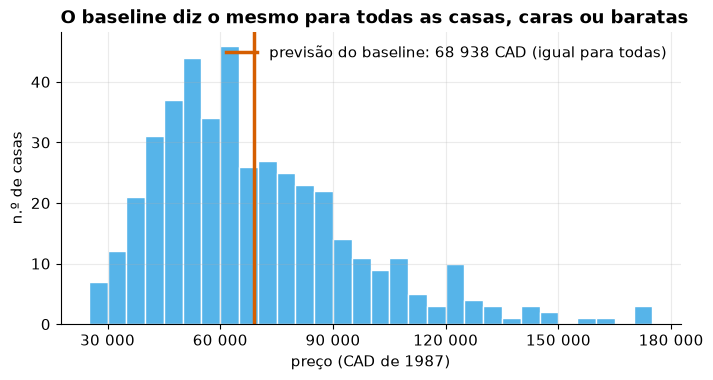

Erro absoluto médio do baseline no treino: 20 835 CAD: é este número que os modelos têm de reduzir.


In [15]:
media = y_train.mean()
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.hist(y_train, bins=30, color=PALETTE["sky"], edgecolor="white")
ax.axvline(media, color=PALETTE["red"], lw=2.5, label=f"previsão do baseline: {fmt_pt(media, 0)} CAD (igual para todas)")
ax.set(xlabel="preço (CAD de 1987)", ylabel="n.º de casas", title="O baseline diz o mesmo para todas as casas, caras ou baratas")
ax.legend()
pt_axis(ax, "x", 0, 6)
pt_axis(ax, "y", 0, 6)
plt.show()
print(f"Erro absoluto médio do baseline no treino: {fmt_pt((y_train - media).abs().mean(), 0)} CAD: é este número que os modelos têm de reduzir.")

### 🧠 Regressão linear: "uma reta (ou plano) que passa o mais perto possível dos pontos"
**Ideia:** o preço previsto é uma **soma ponderada** das características: `preço ≈ b0 + b1·lote + b2·quartos + …`. **Analogia:** uma receita em que cada ingrediente (característica) tem um peso. **Como aprende:** escolhe os pesos que minimizam a soma dos **quadrados dos resíduos** (a distância vertical de cada ponto à reta). **Cuidado:** só apanha relações em linha reta e é sensível a características muito correlacionadas. Abaixo, com **uma só** característica (`lotsize`) para ver o mecanismo; o modelo real usa todas.

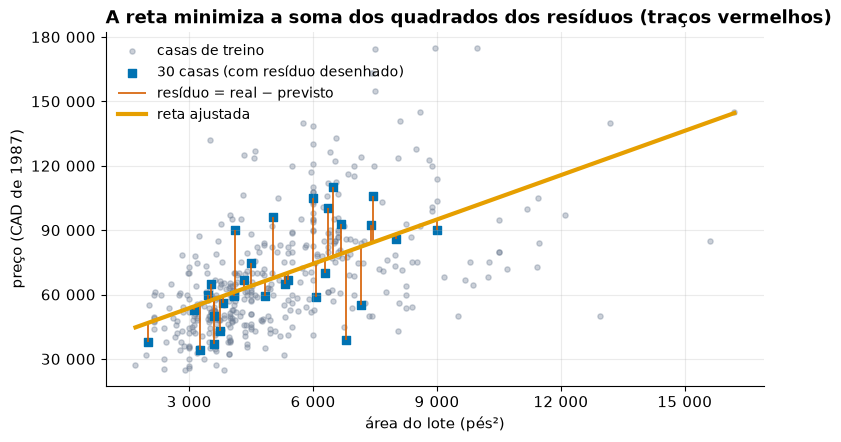

Leitura: cada 1 000 pés² de lote a mais ↔ +6 885 CAD no preço (só com esta característica, sem controlar mais nada).


In [16]:
lin1 = LinearRegression().fit(X_train[["lotsize"]], y_train)
amostra = X_train.assign(price=y_train).sample(30, random_state=1)
grelha = pd.DataFrame({"lotsize": np.linspace(X_train["lotsize"].min(), X_train["lotsize"].max(), 100)})
fig, ax = plt.subplots(figsize=(8.5, 4.6))
ax.scatter(X_train["lotsize"], y_train, s=14, alpha=.35, color=PALETTE["grey"], label="casas de treino")
ax.scatter(amostra["lotsize"], amostra["price"], s=36, marker="s", color=PALETTE["blue"], label="30 casas (com resíduo desenhado)")
ax.vlines(amostra["lotsize"], amostra["price"], lin1.predict(amostra[["lotsize"]]), color=PALETTE["red"], lw=1.2, label="resíduo = real − previsto")
ax.plot(grelha["lotsize"], lin1.predict(grelha), color=PALETTE["orange"], lw=3, label="reta ajustada")
ax.set(xlabel="área do lote (pés²)", ylabel="preço (CAD de 1987)", title="A reta minimiza a soma dos quadrados dos resíduos (traços vermelhos)")
ax.legend(fontsize=10, loc="upper left")
pt_axis(ax, "x", 0, 6)
pt_axis(ax, "y", 0, 6)
plt.show()
print(f"Leitura: cada 1 000 pés² de lote a mais ↔ {fmt_sgn(1000 * lin1.coef_[0], 0)} CAD no preço (só com esta característica, sem controlar mais nada).")

### 🧠 Ridge: "regressão linear com travão nos pesos"
**Ideia:** igual à linear, mas **penaliza pesos grandes** (parâmetro `alpha`, α). **Analogia:** um professor que aceita a explicação mais simples. **Para que serve:** com características correlacionadas, a linear pode dar pesos enormes e opostos; a Ridge estabiliza-os. Com α = 0 é a linear; com α muito grande, todos os pesos tendem para 0 (o baseline). O gráfico mostra o **caminho dos coeficientes** (aqui prevemos `log(preço)`, com as numéricas estandardizadas).

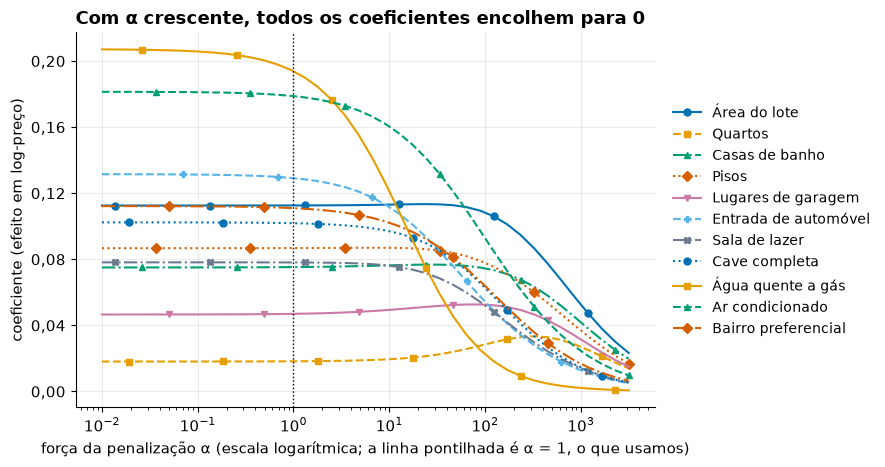

In [17]:
pre_r = make_housing_preprocessor().fit(X_train)
Zs, nomes = pre_r.transform(X_train), pre_r.get_feature_names_out()
alphas = np.logspace(-2, 3.5, 40)
caminho = np.array([Ridge(alpha=a).fit(Zs, np.log(y_train)).coef_ for a in alphas])
cores = plt.rcParams["axes.prop_cycle"].by_key()["color"]
fig, ax = plt.subplots(figsize=(9, 4.8))
for k, nome in enumerate(nomes):
    ax.plot(alphas, caminho[:, k], ls=["-", "--", "-.", ":"][k % 4], marker=MARKERS[k % 7], markevery=(k % 6 + 1, 7), ms=5, color=cores[k % 7], label=TITULOS[nome.replace("_yes", "")])
ax.axvline(1, color="black", lw=1, ls=":")
ax.set_xscale("log")
pt_axis(ax, "y", 2, 6)
ax.set(xlabel="força da penalização α (escala logarítmica; a linha pontilhada é α = 1, o que usamos)",
       ylabel="coeficiente (efeito em log-preço)", title="Com α crescente, todos os coeficientes encolhem para 0")
ax.legend(ncol=1, fontsize=10, loc="center left", bbox_to_anchor=(1.01, 0.5))
fig.tight_layout()
plt.show()

### 🧠 Árvore de decisão: "um jogo de 20 perguntas"
**Ideia:** divide as casas com perguntas sim/não sobre as características (ex.: "lote ≤ 5 000 pés²?") e, em cada "folha", prevê a **média** das casas que lá caíram. **Analogia:** um fluxograma. **Cuidado:** uma árvore profunda decora o treino (*overfitting*), como vais ver na curva de profundidade. Abaixo, uma árvore de **profundidade 2** (as colunas sim/não valem 0 ou 1, por isso "≤ 0,5" significa "não").

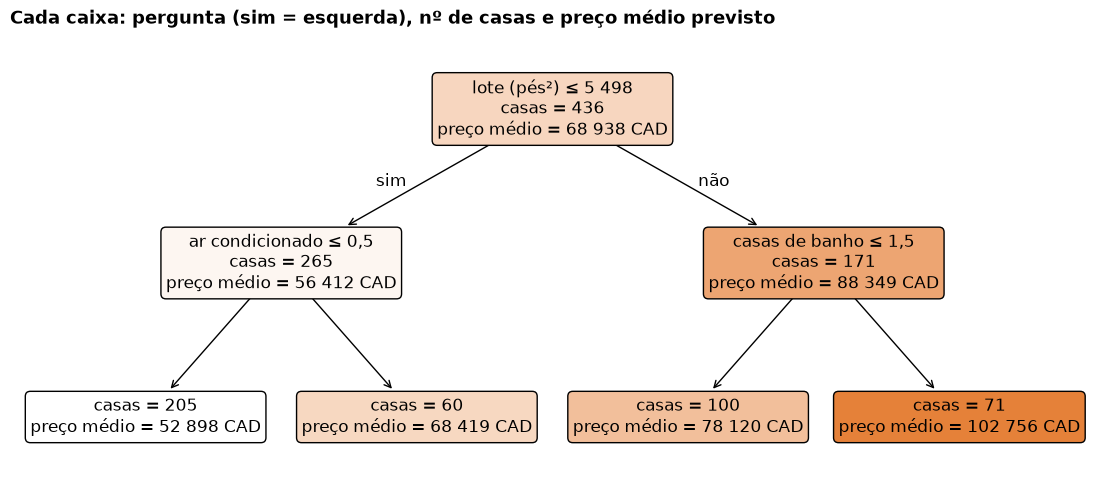

In [18]:
import re

from sklearn.tree import plot_tree

pre_t = make_housing_preprocessor(scale=False).fit(X_train)
Zt = pd.DataFrame(pre_t.transform(X_train), columns=pre_t.get_feature_names_out())
PT = {"lotsize": "lote (pés²)", "bedrooms": "quartos", "bathrooms": "casas de banho", "stories": "pisos", "garage": "garagem",
      "driveway_yes": "entrada de carros", "recreation_yes": "sala de lazer", "fullbase_yes": "cave", "gasheat_yes": "água quente a gás",
      "aircon_yes": "ar condicionado", "prefer_yes": "bairro preferencial"}
tree2 = DecisionTreeRegressor(max_depth=2, random_state=42).fit(Zt, y_train)
fig, ax = plt.subplots(figsize=(14, 6))
notas = plot_tree(tree2, feature_names=[PT.get(n, n) for n in Zt.columns], filled=True, rounded=True, impurity=False, precision=1, fontsize=12, ax=ax)
for t in notas:   # traduz e formata à portuguesa
    txt = t.get_text().replace("samples = ", "casas = ").replace("True", "sim").replace("False", "não")
    txt = re.sub(r"value = ([\d.]+)", lambda m: f"preço médio = {fmt_pt(float(m.group(1)))} CAD", txt)
    txt = re.sub(r"<= ([\d.]+)", lambda m: "≤ " + fmt_pt(float(m.group(1)), 0 if float(m.group(1)) > 100 else 1), txt)
    t.set_text(txt)
ax.set_title("Cada caixa: pergunta (sim = esquerda), nº de casas e preço médio previsto")
plt.show()

### 🧠 Random forest: "pedir a opinião a muitas árvores"
**Ideia:** treina **muitas árvores diferentes** (cada uma vê uma amostra dos dados e só algumas características) e **faz a média** das previsões. **Analogia:** perguntar o preço a 300 avaliadores independentes e fazer a média; os erros individuais cancelam-se em parte. **Cuidado:** perde-se a interpretação direta e, com poucos dados, pode não ganhar a um modelo simples. Abaixo, 5 árvores individuais e a média para 3 casas do teste.

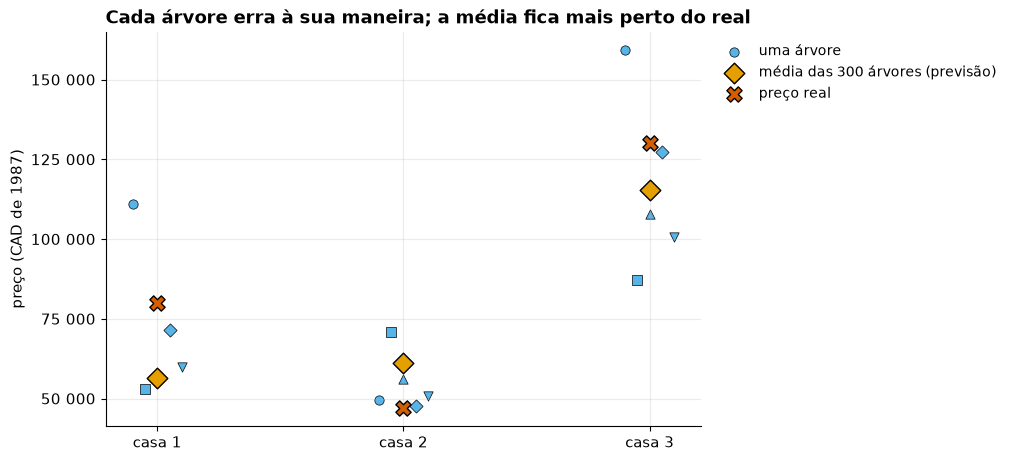

In [19]:
rf_demo = make_pipeline(make_housing_preprocessor(scale=False), RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=42)).fit(X_train, y_train)
casas = X_test.iloc[[0, 1, 2]]
Zc = rf_demo[:-1].transform(casas)
floresta = rf_demo[-1]
por_arvore = np.array([t.predict(Zc) for t in floresta.estimators_[:5]])    # 5 árvores × 3 casas
media_rf = floresta.predict(Zc)
fig, ax = plt.subplots(figsize=(10, 4.5), layout="constrained")
for k in range(5):
    ax.scatter(np.arange(3) + (k - 2) * 0.05, por_arvore[k], marker=MARKERS[k], s=45, color=PALETTE["sky"], edgecolor="black", lw=.5, label="uma árvore" if k == 0 else None)
ax.scatter(np.arange(3), media_rf, marker="D", s=110, color=PALETTE["orange"], edgecolor="black", label="média das 300 árvores (previsão)", zorder=3)
ax.scatter(np.arange(3), y_test.iloc[:3], marker="X", s=120, color=PALETTE["red"], edgecolor="black", label="preço real", zorder=3)
ax.set_xticks(range(3), [f"casa {i + 1}" for i in range(3)])
ax.set(ylabel="preço (CAD de 1987)", title="Cada árvore erra à sua maneira; a média fica mais perto do real")
pt_axis(ax, "y", 0, 6)
ax.legend(fontsize=10, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.show()

### 🧠 (Opcional) *Gradient boosting*: "cada árvore corrige o erro da anterior"
**Ideia:** em vez de árvores independentes, constrói árvores **pequenas em sequência**: a 1.ª aproxima, a 2.ª aprende o erro que sobrou, a 3.ª o erro que ainda sobrou, etc. Exemplo didático com **uma só** característica (`lotsize`) e 3 árvores de 1 pergunta: não chega para acertar todas as casas, mas mostra o mecanismo.

In [20]:
from sklearn.ensemble import GradientBoostingRegressor

gb = GradientBoostingRegressor(n_estimators=3, max_depth=1, learning_rate=1.0, random_state=0).fit(df[["lotsize"]], df["price"])
etapas = list(gb.staged_predict(df[["lotsize"]]))
quadro = pd.DataFrame({"preço real": [df["price"][i] for i in (0, 10)],
                       "início (média de todas)": [df["price"].mean()] * 2,
                       "após árvore 1": [etapas[0][i] for i in (0, 10)],
                       "após árvore 2": [etapas[1][i] for i in (0, 10)],
                       "após árvore 3": [etapas[2][i] for i in (0, 10)]}, index=["casa nº 0", "casa nº 10"])
quadro.round(0).astype(int)

,preço real,início (média de todas),após árvore 1,após árvore 2,após árvore 3
casa nº 0,42000,68122,57639,61346,63483
casa nº 10,90000,68122,88745,92452,87156


Cada coluna é a previsão **depois de somar mais uma árvore**: a previsão começa na média e vai sendo corrigida. Com mais árvores e mais características, o *boosting* é muitas vezes o modelo mais forte em dados tabulares (voltas a vê-lo no notebook 02 como `HistGradientBoosting`).

In [21]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)


def log_model(regressor):
    """Pipeline (pré-processamento + modelo) que prevê log(preço) mas devolve CAD."""
    return TransformedTargetRegressor(regressor=make_pipeline(make_housing_preprocessor(), regressor),
                                      func=np.log, inverse_func=np.exp)


models = {
    "Baseline (média)": DummyRegressor(strategy="mean"),
    "Linear (log preço)": log_model(LinearRegression()),
    "Ridge α=1 (log preço)": log_model(Ridge(alpha=1.0)),
    "Random forest": make_pipeline(make_housing_preprocessor(), RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=42)),
}

rows = {}
for name, model in models.items():
    r = cross_validate(model, X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error")
    rows[name] = {"CV RMSE (CAD)": -r["test_score"].mean(), "± desvio": r["test_score"].std()}
cv_table = pd.DataFrame(rows).T
cv_table.round(0).astype(int)

,CV RMSE (CAD),± desvio
Baseline (média),26825,1345
Linear (log preço),15419,1134
Ridge α=1 (log preço),15419,1125
Random forest,16406,1292


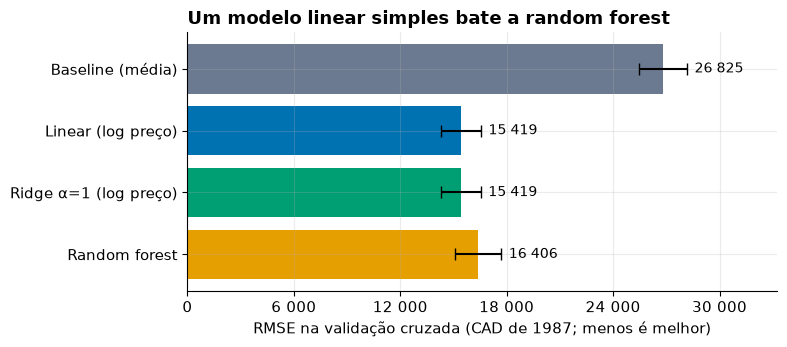

In [22]:
fig, ax = plt.subplots(figsize=(8, 3.6))
cores = [PALETTE["grey"], PALETTE["blue"], PALETTE["green"], PALETTE["orange"]]
ax.barh(cv_table.index[::-1], cv_table["CV RMSE (CAD)"][::-1], xerr=cv_table["± desvio"][::-1], color=cores[::-1], capsize=4)
label_bars(ax, cv_table["CV RMSE (CAD)"][::-1].values, cv_table["± desvio"][::-1].values)
pt_axis(ax, "x", 0, 6)
ax.set(xlabel="RMSE na validação cruzada (CAD de 1987; menos é melhor)", title="Um modelo linear simples bate a random forest")
fig.tight_layout()
save_fig(fig, FIG / "01_model_comparison.png")
plt.show()

### Complexidade vs. *overfitting*: a profundidade de uma árvore
Uma árvore de decisão com poucos níveis é simples; com muitos, **decora** o treino. Medimos o RMSE no treino e na validação (5-fold) para cada profundidade máxima.

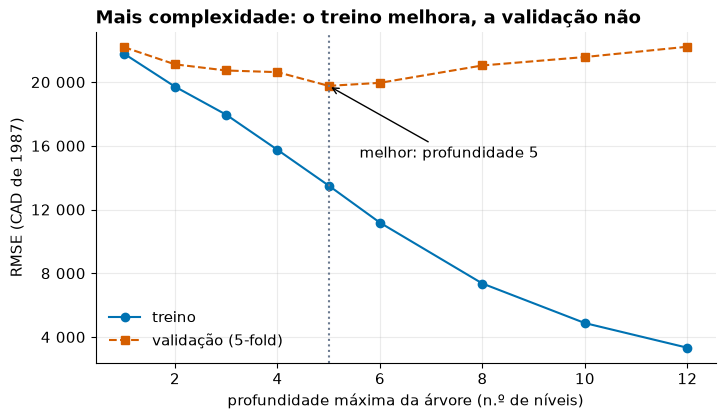

Profundidade 12: treino 3 325 CAD vs. validação 22 218 CAD → distância de 18 893 CAD (overfitting).


In [23]:
depths = [1, 2, 3, 4, 5, 6, 8, 10, 12]
tr, va = [], []
for d in depths:
    tree = make_pipeline(make_housing_preprocessor(scale=False), DecisionTreeRegressor(max_depth=d, random_state=42))
    r = cross_validate(tree, X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error", return_train_score=True)
    tr.append(-r["train_score"].mean())
    va.append(-r["test_score"].mean())
best_d = depths[int(np.argmin(va))]

fig, ax = plt.subplots(figsize=(8, 4.3))
ax.plot(depths, tr, marker="o", color=PALETTE["blue"], label="treino")
ax.plot(depths, va, marker="s", color=PALETTE["red"], ls="--", label="validação (5-fold)")
ax.axvline(best_d, color=PALETTE["grey"], ls=":")
ax.annotate(f"melhor: profundidade {best_d}", (best_d, min(va)), xytext=(best_d + 0.6, min(va) - 4500), arrowprops={"arrowstyle": "->"})
ax.set(xlabel="profundidade máxima da árvore (n.º de níveis)", ylabel="RMSE (CAD de 1987)",
       title="Mais complexidade: o treino melhora, a validação não")
ax.legend()
pt_axis(ax, "y", 0, 6)
save_fig(fig, FIG / "01_depth_curve.png")
plt.show()
print(f"Profundidade {depths[-1]}: treino {fmt_pt(tr[-1], 0)} CAD vs. validação {fmt_pt(va[-1], 0)} CAD → distância de {fmt_pt(va[-1] - tr[-1], 0)} CAD (overfitting).")

### 💬 Discussão — Porque é que o modelo mais complexo não ganha?
A *random forest* é, em geral, mais flexível que a regressão linear e ainda assim fica pior na validação. Porquê? Em que condições esperarias o contrário?

<details>
<summary>🧑‍🏫 Resposta-guia para o instrutor</summary>

Na validação cruzada, a Ridge tem RMSE ≈ **15 400** e a random forest ≈ **16 400** (esta prevê o preço diretamente em CAD; as árvores não precisam de log para lidar com assimetria nas entradas) (e a diferença confirma-se no teste: R² 0,642 vs 0,590). Com apenas **546** casas e relações muito próximas de lineares **no log**, o modelo flexível tem pouco que "descobrir" para além de ruído e paga variância. O gráfico da profundidade mostra o mesmo mecanismo: o erro de treino cai para ≈ 3 300 CAD na profundidade 12 enquanto o de validação sobe para ≈ 22 000 (a melhor profundidade é a do mínimo da curva vermelha, ≈ 6). Esperaríamos o contrário com **muito mais dados**, interações fortes (ex.: o efeito de `aircon` depende do bairro) ou variáveis geográficas contínuas. Moral: **simplicidade primeiro**; só se complica quando a validação o justifica.
</details>

### ✏️ Exercício 1 — Quanto vale a sorte do *split*?
**Dificuldade:** ⭐

O R² do teste depende da divisão aleatória. Repete o treino da Ridge com 10 sementes diferentes (`random_state` de 0 a 9) e vê a variação do R². Completa o `TODO`.

In [24]:
r2s = []
for seed in range(10):
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=seed)
    m = log_model(Ridge(alpha=1.0)).fit(Xtr, ytr)
    r2s.append(r2_score(yte, m.predict(Xte)))
# TODO: mostra a média e o desvio-padrão dos R² (e pensa: confias numa única divisão?)
print(np.round(r2s, 2))

[0.61 0.67 0.66 0.53 0.61 0.74 0.6  0.75 0.62 0.71]


<details>
<summary>💡 Ver solução</summary>

```python
r2s = []
for seed in range(10):
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=seed)
    m = log_model(Ridge(alpha=1.0)).fit(Xtr, ytr)
    r2s.append(r2_score(yte, m.predict(Xte)))
print(f"R² médio {fmt_pt(np.mean(r2s), 3)} ± {fmt_pt(np.std(r2s), 3)}  (min {fmt_pt(min(r2s), 2)}, max {fmt_pt(max(r2s), 2)})")
```

O R² varia vários pontos percentuais só com a semente. Com 110 casas de teste, **um único número é frágil**: é por isso que usamos validação cruzada para comparar modelos e reportamos o desvio.
</details>

<a id="sec-5"></a>
# 5. 📏 Evaluation (avaliação)

Só agora abrimos o "cofre": ajustamos cada modelo ao treino completo e medimos no **teste**, nunca visto. Quatro métricas:

- **MAE** (erro absoluto médio, CAD): "em média erra X dólares";
- **RMSE** (CAD): como o MAE, mas castiga erros grandes;
- **R²**: fração da variabilidade do preço explicada (0 = como a média; 1 = perfeito; pode ser negativo);
- **MAPE** (erro percentual absoluto médio): "em média erra X %": a métrica que o negócio entende.

In [25]:
def evaluate(model, X_te, y_te):
    pred = model.predict(X_te)
    return {"MAE (CAD)": mean_absolute_error(y_te, pred),
            "RMSE (CAD)": mean_squared_error(y_te, pred) ** 0.5,
            "R²": r2_score(y_te, pred),
            "MAPE (%)": 100 * mean_absolute_percentage_error(y_te, pred)}


fitted = {name: m.fit(X_train, y_train) for name, m in models.items()}
test_table = pd.DataFrame({name: evaluate(m, X_test, y_test) for name, m in fitted.items()}).T
test_table.round({"MAE (CAD)": 0, "RMSE (CAD)": 0, "R²": 3, "MAPE (%)": 1})

,MAE (CAD),RMSE (CAD),R²,MAPE (%)
Baseline (média),20313.0,26163.0,-0.025,36.1
Linear (log preço),10750.0,15475.0,0.642,17.5
Ridge α=1 (log preço),10735.0,15457.0,0.642,17.5
Random forest,12222.0,16538.0,0.591,19.9


> ✅ O modelo linear/Ridge reduz o erro do *baseline* de ≈ 20 300 para ≈ 10 700 CAD (MAE). Repara que o **R² do baseline é ≈ 0** (ligeiramente negativo): "prever a média" não explica nada, e é a fasquia a bater.

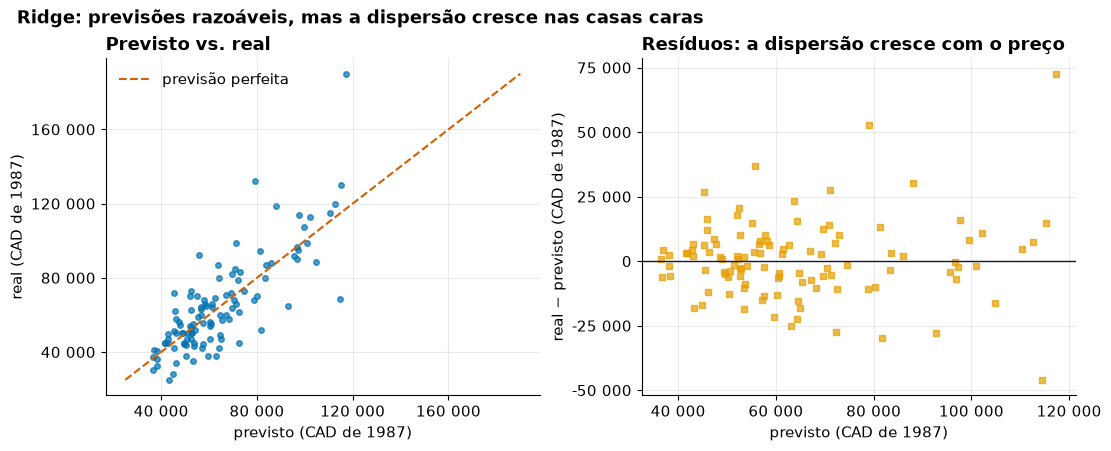

In [26]:
ridge = fitted["Ridge α=1 (log preço)"]
pred_test = ridge.predict(X_test)
fig = plot_residuals(y_test, pred_test, unit="CAD de 1987", title="Resíduos: a dispersão cresce com o preço")
fig.suptitle("Ridge: previsões razoáveis, mas a dispersão cresce nas casas caras", x=0.01, ha="left", fontweight="bold")
save_fig(fig, FIG / "01_residuals.png")
plt.show()

### 5.1 O que pesa mais? Coeficientes da Ridge como percentagens

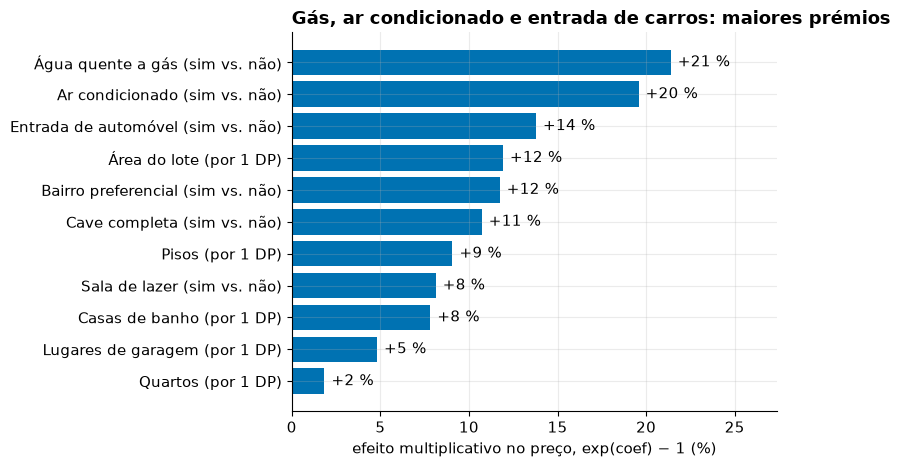

,gasheat_yes,aircon_yes,driveway_yes,lotsize,prefer_yes,fullbase_yes,stories,recreation_yes,bathrooms,garage,bedrooms
efeito (%),21.4,19.6,13.8,11.9,11.7,10.7,9.1,8.1,7.8,4.8,1.8


In [27]:
pre_fitted = ridge.regressor_.named_steps["columntransformer"]
coef = pd.Series(ridge.regressor_.named_steps["ridge"].coef_, index=pre_fitted.get_feature_names_out())
effects = ((np.exp(coef) - 1) * 100).sort_values()   # efeito multiplicativo em %
labels = [f"{TITULOS[n]} (por 1 DP)" if n in HOUSING_NUMERIC else f"{TITULOS[n.replace('_yes', '')]} (sim vs. não)" for n in effects.index]

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.barh(labels, effects.values, color=[PALETTE["blue"] if v > 0 else PALETTE["red"] for v in effects])
for i, v in enumerate(effects.values):
    ax.text(v + 0.4, i, f"{fmt_sgn(v, 0)} %", va="center")
ax.set(xlabel="efeito multiplicativo no preço, exp(coef) − 1 (%)", title="Gás, ar condicionado e entrada de carros: maiores prémios")
ax.set_xlim(0, effects.max() + 6)
pt_axis(ax, "x", 0, 6)
fig.tight_layout()
save_fig(fig, FIG / "01_ridge_effects.png")
plt.show()
effects.sort_values(ascending=False).round(1).to_frame("efeito (%)").T

> 💡 **Como ler:** nas variáveis numéricas (estandardizadas) o efeito é **por 1 desvio-padrão (DP)**, por exemplo +12 % por cada ≈ 2 170 pés² a mais de lote; nas sim/não é o efeito de **ter** a característica, **mantendo as outras iguais**. Os coeficientes **não são comparáveis** entre uma variável contínua e uma binária sem esta ressalva.

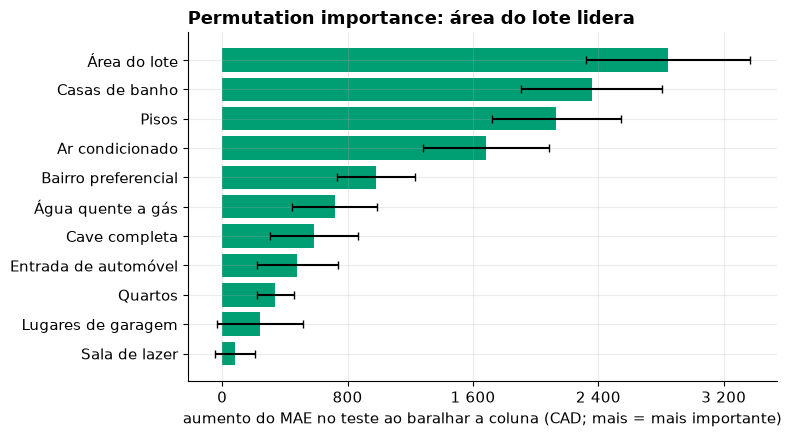

Top 3 por permutation importance: ['lotsize', 'bathrooms', 'stories']


In [28]:
imp = permutation_importance(ridge, X_test, y_test, scoring="neg_mean_absolute_error", n_repeats=20, random_state=42)
perm = pd.Series(imp.importances_mean, index=X_test.columns).sort_values()
perm_std = pd.Series(imp.importances_std, index=X_test.columns)[perm.index]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh([TITULOS[c] for c in perm.index], perm.values, xerr=perm_std.values, color=PALETTE["green"], capsize=3)
ax.set(xlabel="aumento do MAE no teste ao baralhar a coluna (CAD; mais = mais importante)", title=f"Permutation importance: {TITULOS[perm.index[-1]].lower()} lidera")
pt_axis(ax, "x", 0, 6)
fig.tight_layout()
save_fig(fig, FIG / "01_permutation_importance.png")
plt.show()
print("Top 3 por permutation importance:", list(perm.sort_values(ascending=False).index[:3]))

A *permutation importance* mede **quanto piora o erro** se baralharmos uma coluna (destrói a sua informação). É diferente dos coeficientes: um coeficiente grande numa característica **rara** (`gasheat`: só 25 casas!) pesa pouco na prática, porque afeta poucas previsões. Por isso as duas vistas dão rankings diferentes, e **ambas são úteis**.

### 5.2 Revisitar as tuas hipóteses

In [29]:
ranking_coef = [n.replace("_yes", "") for n in effects.sort_values(ascending=False).index[:3]]
ranking_perm = list(perm.sort_values(ascending=False).index[:3])
print("Os dados dizem:")
print(f"  • Maiores efeitos (coeficientes):      {ranking_coef}")
print(f"  • Mais importantes (permutation imp.): {ranking_perm}")
print(f"  • Ar condicionado: {fmt_sgn(effects['aircon_yes'], 0)} % (mantendo o resto igual)")
print(f"  • Erro relativo médio no teste (MAPE): {fmt_pt(test_table.loc['Ridge α=1 (log preço)', 'MAPE (%)'], 1)} %")
print("\nAs tuas hipóteses:", {k: v for k, v in my_hypotheses.items() if v not in ('', None)} or "(ainda vazias: preenche a célula da secção 1 e volta aqui)")

Os dados dizem:
  • Maiores efeitos (coeficientes):      ['gasheat', 'aircon', 'driveway']
  • Mais importantes (permutation imp.): ['lotsize', 'bathrooms', 'stories']
  • Ar condicionado: +20 % (mantendo o resto igual)
  • Erro relativo médio no teste (MAPE): 17,5 %

As tuas hipóteses: (ainda vazias: preenche a célula da secção 1 e volta aqui)


### 💬 Discussão — A tua intuição bateu certo?
Compara as tuas hipóteses com o ranking dos coeficientes e da *permutation importance*. Onde errou a intuição, e porquê? Há diferenças entre os dois rankings, o que significam?

<details>
<summary>🧑‍🏫 Resposta-guia para o instrutor</summary>

Resposta típica: muita gente aposta em `bedrooms`, mas o efeito é só ≈ **+2 % por DP**: o n.º de quartos pesa pouco **depois de controlar** lote, casas de banho e pisos (estão correlacionados). Os maiores prémios por coeficiente são `gasheat` (≈ +21 %), `aircon` (≈ +20 %) e `driveway` (≈ +14 %), mas `gasheat` ocorre em apenas **25 de 546** casas, por isso a *permutation importance* destaca antes variáveis frequentes e com muita variação (ver o gráfico: o topo é o do ranking impresso acima). Dois rankings, duas perguntas: "qual o efeito de ter X?" vs. "quanto o modelo depende de X para prever?". Convém ainda lembrar que coeficientes são **associações condicionais**, não causas.
</details>

### 5.3 Os 5 maiores erros: onde falha o modelo?

In [30]:
err = pd.DataFrame({"preço real": y_test, "previsto": pred_test.round(0)})
err["erro"] = err["preço real"] - err["previsto"]
err["erro %"] = (100 * err["erro"] / err["preço real"]).round(0)
top5 = err.reindex(err["erro"].abs().sort_values(ascending=False).index).head(5)
display(top5.join(X_test[["lotsize", "bedrooms", "bathrooms", "stories", "aircon", "prefer"]]))
print(f"Estes 5 casos representam {fmt_pt(100 * (top5['erro'].abs().sum() / err['erro'].abs().sum()), 0)} % do erro absoluto total ({len(err)} casas de teste).")

,preço real,previsto,erro,erro %,lotsize,bedrooms,bathrooms,stories,aircon,prefer
377,190000,117365.0,72635.0,38.0,7420,4,2,3,yes,yes
436,132000,79142.0,52858.0,40.0,7800,3,2,2,no,yes
501,68500,114492.0,-45992.0,-67.0,8100,4,1,4,yes,no
209,92500,55668.0,36832.0,40.0,3960,3,1,1,no,no
485,118500,88052.0,30448.0,26.0,4880,4,2,2,yes,yes


Estes 5 casos representam 20 % do erro absoluto total (110 casas de teste).


### 💬 Discussão — O que têm em comum as 5 piores previsões?
Observa a tabela. São casas "normais"? Que informação teria ajudado o modelo? O que farias com elas: remover, investigar, ou aceitar?

<details>
<summary>🧑‍🏫 Resposta-guia para o instrutor</summary>

Os maiores erros são casas **muito acima** do previsto (ex.: uma casa vendida por **190 000** CAD com previsão ≈ **117 000**, lote grande, 2 casas de banho, bairro preferencial) e uma ou outra **abaixo** (casa de 4 quartos prevista a ≈ 114 000 mas vendida a 68 500, com 1 casa de banho, sem ar condicionado). Em ambos os sentidos faltam fatores **ocultos**: área habitável, estado, localização exata, ano. Não se removem: são parte do problema real e o erro é **irredutível** com estes dados. Aceitar, **documentar** e comunicar que o intervalo de erro é maior para casas caras (como os resíduos mostram).
</details>

### ✏️ Exercício 2 — Erro por faixa de preço
**Dificuldade:** ⭐⭐

O MAPE médio esconde que o erro não é igual para todas as casas. Divide o teste em 3 faixas de preço (tercis) e calcula o MAPE em cada uma. Completa o `TODO`.

In [31]:
faixas = pd.qcut(y_test, 3, labels=["baratas", "médias", "caras"])
res = pd.DataFrame({"real": y_test, "previsto": pred_test, "faixa": faixas})
# TODO: calcula o MAPE (em %) por faixa com groupby
res.groupby("faixa", observed=True)["real"].agg(["count", "median"])

,count,median
faixa,,
baratas,39,44500.0
médias,34,60000.0
caras,37,88000.0


<details>
<summary>💡 Ver solução</summary>

```python
faixas = pd.qcut(y_test, 3, labels=["baratas", "médias", "caras"])
res = pd.DataFrame({"real": y_test, "previsto": pred_test, "faixa": faixas})
res["ape"] = 100 * (res["real"] - res["previsto"]).abs() / res["real"]
res.groupby("faixa", observed=True).agg(casas=("real", "size"), preco_mediano=("real", "median"), MAPE_pct=("ape", "mean"))
```

Em regra, o erro relativo é maior nas casas baratas (o modelo tende a sobrestimá-las) e o erro absoluto maior nas caras. Um único MAPE global **esconde desigualdades**: reporta sempre por segmento relevante.
</details>

<a id="sec-6"></a>
# 6. 🚀 Deployment (implementação)

Um modelo que só vive no notebook não serve ninguém. Implementar é: (1) **guardar** o *pipeline* completo (pré-processamento + modelo, nunca só o modelo); (2) expô-lo através de uma função/serviço com **entradas validadas**; (3) **monitorizar** em produção.

Para o modelo final, voltamos a treinar a Ridge com **todos os dados** (treino + teste): já escolhemos o modelo e o teste cumpriu o seu papel; a partir daqui, mais dados valem mais do que um cofre.

In [32]:
final_model = log_model(Ridge(alpha=1.0)).fit(X, y)
caminho = models_dir() / "house_price_ridge.joblib"
joblib.dump(final_model, caminho)
print(f"Guardado em: models/{caminho.name} ({fmt_pt(caminho.stat().st_size / 1024, 0)} KB)")

modelo = joblib.load(caminho)                      # em produção: carregar uma vez, usar muitas
print("Recarregado e idêntico:", np.allclose(modelo.predict(X.head()), final_model.predict(X.head())))

Guardado em: models/house_price_ridge.joblib (6 KB)
Recarregado e idêntico: True


In [33]:
# Valores por omissão = o "caso típico" do treino (mediana / valor mais frequente)
DEFAULTS = {c: X[c].median() for c in HOUSING_NUMERIC} | {c: X[c].mode()[0] for c in HOUSING_BINARY}
RANGES = {c: (X[c].min(), X[c].max()) for c in HOUSING_NUMERIC}


def predict_price(**features) -> float:
    """Previsão do preço (CAD de 1987) para uma casa. Ex.: predict_price(lotsize=6000, bathrooms=2, aircon="yes")."""
    unknown = set(features) - set(DEFAULTS)
    if unknown:
        raise ValueError(f"Características desconhecidas: {sorted(unknown)}. Válidas: {sorted(DEFAULTS)}")
    row = DEFAULTS | features
    for c in HOUSING_BINARY:
        if row[c] not in ("yes", "no"):
            raise ValueError(f"{c} deve ser 'yes' ou 'no', não {row[c]!r}")
    for c, (lo, hi) in RANGES.items():
        if not lo <= row[c] <= hi:
            warnings.warn(f"{c}={row[c]} está fora do intervalo visto no treino [{lo}, {hi}]: previsão pouco fiável.", stacklevel=2)
    return float(modelo.predict(pd.DataFrame([row])[X.columns])[0])


print(f"Casa típica:                          {fmt_pt(predict_price(), 0):>9} CAD")
print(f"Casa de 6 000 pés², 2 casas de banho: {fmt_pt(predict_price(lotsize=6000, bathrooms=2), 0):>9} CAD")
print(f"... e com ar condicionado:            {fmt_pt(predict_price(lotsize=6000, bathrooms=2, aircon='yes'), 0):>9} CAD")

Casa típica:                             51 232 CAD
Casa de 6 000 pés², 2 casas de banho:    65 049 CAD
... e com ar condicionado:               77 570 CAD


### 🔧 E se a casa tiver **+1 casa de banho**? (contrafactual simples)
Podemos pedir ao modelo duas previsões que diferem só numa característica:

In [34]:
base = dict(lotsize=5000, bedrooms=3, bathrooms=1, stories=2, garage=1)
a, b = predict_price(**base), predict_price(**{**base, "bathrooms": 2})
print(f"1 casa de banho: {fmt_pt(a, 0)} CAD · 2 casas de banho: {fmt_pt(b, 0)} CAD → diferença {fmt_sgn(b - a, 0)} CAD ({fmt_sgn(100 * ((b / a - 1)), 0)} %)")

1 casa de banho: 55 020 CAD · 2 casas de banho: 65 077 CAD → diferença +10 057 CAD (+18 %)


> ⚠️ **Cuidado:** isto é a **associação** que o modelo aprendeu em 1987, mantendo o resto igual, **não** o retorno garantido de construir uma casa de banho. Na pergunta-bónus (secção 7) voltamos a isto.

### Limites e monitorização
- **1987!** O modelo conhece Windsor no verão de 1987. Aplicado a hoje (outra cidade, outro nível de preços, outras casas), é inútil. Os dados mudam: é a **deriva** (*drift*).
- **Entradas fora do intervalo** (ex.: lote de 50 000 pés²): o modelo extrapola sem aviso; a função acima emite um aviso.
- **Monitorizar**: quando houver preços reais de venda, comparar com as previsões e vigiar o MAPE; se subir de um limiar, **retreinar**.

In [35]:
# Simulação (hipotética): os preços sobem muito, mas o modelo continua o de 1987
mape = lambda real, prev: 100 * mean_absolute_percentage_error(real, prev)
for fator in (1.0, 1.2, 1.6):
    m = mape(y_test * fator, ridge.predict(X_test))
    alerta = "  ⚠️ ALERTA: retreinar" if m > 25 else ""
    print(f"Preços ×{fmt_pt(fator, 1)} → MAPE {fmt_pt(m, 1):>5} %{alerta}")

Preços ×1,0 → MAPE  17,5 %
Preços ×1,2 → MAPE  20,7 %
Preços ×1,6 → MAPE  35,2 %  ⚠️ ALERTA: retreinar


### 💬 Discussão — Do notebook para o mundo real
Quem deveria ver o aviso "fora do intervalo"? Que três coisas monitorizarias numa versão real deste modelo, e o que acionaria o retreino?

<details>
<summary>🧑‍🏫 Resposta-guia para o instrutor</summary>

Quem **usa** a previsão (agente/banco), mostrado junto com a previsão, não escondido num registo técnico. A simulação mostra o risco: se os preços subirem 60 % o MAPE passa de ≈ 17 % para bem acima do limiar de 25 %, sem que o código dê erro nenhum: o modelo falha **em silêncio**. Monitorizar: (1) **erro** quando chegam os preços reais; (2) **distribuição das entradas** (lote, casas de banho) face ao treino; (3) **distribuição das previsões**. O retreino é acionado por um limiar combinado com o negócio (ex.: MAPE > 25 % durante um mês) e por mudanças conhecidas (nova cidade, novos tipos de casa).
</details>

### ✏️ Exercício 3 — A tua casa
**Dificuldade:** ⭐

Usa `predict_price` para estimar o preço de uma casa que imaginas (ou da tua!). Muda 2-3 características e compara. O que acontece se pedires `lotsize=40000`?

In [36]:
# TODO: altera os valores à vontade
print(f"{fmt_pt(predict_price(lotsize=4500, bedrooms=2, bathrooms=1), 0)} CAD")
print(f"{fmt_pt(predict_price(lotsize=4500, bedrooms=2, bathrooms=1, garage=2, aircon='yes'), 0)} CAD")

49 262 CAD


65 063 CAD


<details>
<summary>💡 Ver solução</summary>

```python
print(f"{fmt_pt(predict_price(lotsize=4500, bedrooms=2, bathrooms=1), 0)} CAD")
print(f"{fmt_pt(predict_price(lotsize=4500, bedrooms=2, bathrooms=1, garage=2, aircon='yes'), 0)} CAD")
with warnings.catch_warnings(record=True) as w:
    warnings.simplefilter("always")
    p = predict_price(lotsize=40000)
    print(f"lotsize=40000 → {fmt_pt(p, 0)} CAD; aviso: {w[0].message if w else 'nenhum'}")
```

O lote de 40 000 pés² está muito fora do treino (máx. 16 200): o modelo devolve um número, mas **não é fiável**. É por isso que validamos e avisamos as entradas.
</details>

<a id="sec-7"></a>
# 7. 🎁 Pergunta-bónus: devo remodelar?

> **"O modelo pode decidir quanto investir numa remodelação?"** Um proprietário pergunta: *"se juntar uma casa de banho por 8 000 CAD, o modelo diz que a casa sobe de preço. Compensa?"*

### 💬 Discussão — Preditivo vs. causal
O modelo prevê bem o preço de casas que **já existem**. Isso chega para decidir uma **intervenção** (construir, instalar ar condicionado)? Porquê, ou porque não?

<details>
<summary>🧑‍🏫 Resposta-guia para o instrutor</summary>

Não necessariamente. O modelo responde "**quanto custam, em média, casas que *têm* uma 2.ª casa de banho** (mantendo o resto igual)?", uma pergunta **preditiva/associativa**. Para decidir remodelar precisamos do **efeito causal**: "quanto sobe *esta* casa se *eu* construir?". Diferem porque (i) casas com 2 casas de banho têm também lotes maiores, melhores bairros, etc., e só controlámos o que está nos dados (falta área habitável, estado, localização); (ii) uma casa de banho prevista de raiz é diferente de uma acrescentada; (iii) o preço depende do **mercado de 1987**. Para estimar causas há desenhos próprios (experiências, quase-experiências, modelos causais). O modelo serve para uma **estimativa de ordem de grandeza**, nunca para provar retorno. Extensões como **SHAP** (contribuição de cada característica por casa) e **PDP** (curvas de dependência parcial) explicam *o modelo*, não o *mundo*.
</details>

<a id="sec-8"></a>
# 8. 📌 Resumo

| Fase CRISP-DM | O que fizemos | Lição |
|---|---|---|
| 🧭 Business Understanding | Utilizadores, "bom" = erro % tolerável, hipóteses escritas | Definir o sucesso **antes** de modelar |
| 🔎 Data Understanding | Preço assimétrico, correlações, *outliers* reais, confusão (`bathrooms`/`lotsize`) | Correlação ≠ causa; saber o que **falta** |
| 🧹 Data Preparation | Split primeiro, *pipeline*, `log(preço)` | Nada que "aprenda" toca no teste |
| 🤖 Modeling | Baseline, linear, Ridge, RF; CV; curva de profundidade | Simplicidade primeiro; vigiar *overfitting* |
| 📏 Evaluation | MAE/RMSE/R²/MAPE, coeficientes em %, *permutation importance*, maiores erros | Métrica **de negócio** + onde falha |
| 🚀 Deployment | `joblib`, `predict_price`, limites, monitorização | 1987, deriva, preditivo ≠ causal |

**✅ Checklist:**
- [ ] Defini "bom" em termos de negócio antes de modelar?
- [ ] Dividi os dados **antes** de ajustar qualquer coisa?
- [ ] Comparei com um *baseline* e usei validação cruzada?
- [ ] Reportei o erro em unidades que o utilizador entende?
- [ ] Investiguei os maiores erros e os limites do modelo?
- [ ] Sei dizer o que o modelo **não** pode responder?

<a id="sec-9"></a>
# 9. 📚 Para saber mais

> 📚 **Para saber mais**
> - Chapman et al. (2000). *CRISP-DM 1.0: Step-by-step data mining guide*. SPSS / NCR / DaimlerChrysler.
> - scikit-learn User Guide: [*Pipelines e ColumnTransformer*](https://scikit-learn.org/stable/modules/compose.html) · [Validação cruzada](https://scikit-learn.org/stable/modules/cross_validation.html) · [Métricas](https://scikit-learn.org/stable/modules/model_evaluation.html) · [*Common pitfalls* (leakage)](https://scikit-learn.org/stable/common_pitfalls.html) · [Escolher um estimador](https://scikit-learn.org/stable/machine_learning_map.html)
> - Anglin, P. M. & Gençay, R. (1996). *Semiparametric estimation of a hedonic price function*. *Journal of Applied Econometrics*, 11(6), 633-648. Dados: arquivo oficial do JAE, <http://qed.econ.queensu.ca/jae/1996-v11.6/anglin-gencay/>.
>
> 🤖 **Ligação à IA:** grandes modelos de linguagem são também treinados com um passo supervisionado, só que o "alvo" é a próxima palavra. As ideias de *overfitting*, validação e *leakage* aplicam-se igualmente.

---
<div align="center">

⬅️ [Lição 02 · início](../../README.md) &nbsp;·&nbsp; 🏠 [Lição 02](../../README.md) &nbsp;·&nbsp; [Seguinte: 02 · CRISP-DM: Titanic](02_CRISP-DM_Titanic_Survival.ipynb) ➡️

**The AI Learning Hub** · Lição 02 — Machine Learning: fundamentos<br>
Diogo Freitas & João Francisco Botas · Licença MIT

</div>